# Drift-Triggered Retraining with an Orchestrated Serverless Endpoint

## Main Jupyter notebook — Tasks 1–7 with numbered code sections

**Run every code cell from top to bottom.** Each task is broken into numbered subparts (1.1, 1.2, 1.3 …), and each subpart has its own code cell and saved evidence. The notebook distinguishes local endpoint benchmarking from a real cloud deployment.

In [1]:
from pathlib import Path
import json, time, hashlib, shutil, warnings, platform
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.base import clone

RANDOM_STATE = 42
# Find the project folder even when Jupyter starts in a different working directory.
_here = Path.cwd().resolve()
_candidates = [_here, *_here.parents]
PROJECT_ROOT = next((p for p in _candidates if (p / "data" / "churn_reference_train.csv").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find data/churn_reference_train.csv. Extract the project ZIP, "
        "then open this notebook from inside the extracted project folder."
    )
DATA_DIR = PROJECT_ROOT / "data"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts"
MODEL_DIR = ARTIFACT_DIR / "models"
REPORT_DIR = ARTIFACT_DIR / "reports"
LOG_DIR = ARTIFACT_DIR / "logs"
for folder in [MODEL_DIR, REPORT_DIR, LOG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Python:", platform.python_version())
print("Project root:", PROJECT_ROOT)
print("CSV files:", len(list(DATA_DIR.glob("*.csv"))))


Python: 3.13.3
Project root: D:\drift-triggered-retraining
CSV files: 9


## Task 1 — Baseline model and registry

### 1.1 — Validate the supplied files and inspect the reference data

### 1.1.1 — Check all nine CSV files exist and save a data inventory

In [2]:
expected_files = ["churn_reference_train.csv"] + [f"churn_week_{i}.csv" for i in range(1, 9)]
missing_files = [f for f in expected_files if not (DATA_DIR / f).exists()]
if missing_files:
    raise FileNotFoundError(f"Missing CSV files in {DATA_DIR}: {missing_files}")

data_inventory = []
for name in expected_files:
    df_check = pd.read_csv(DATA_DIR / name)
    data_inventory.append({
        "file": name,
        "rows": len(df_check),
        "columns": len(df_check.columns),
        "missing_cells": int(df_check.isna().sum().sum()),
        "column_names": ", ".join(df_check.columns.astype(str))
    })
inventory_df = pd.DataFrame(data_inventory)
display(inventory_df[["file", "rows", "columns", "missing_cells"]])
inventory_df.to_json(REPORT_DIR / "data_inventory.json", orient="records", indent=2)


,file,rows,columns,missing_cells
0,churn_reference_train.csv,3000,10,105
1,churn_week_1.csv,500,11,18
2,churn_week_2.csv,500,11,18
3,churn_week_3.csv,500,11,18
4,churn_week_4.csv,500,11,18
5,churn_week_5.csv,500,11,18
6,churn_week_6.csv,500,11,18
7,churn_week_7.csv,500,11,18
8,churn_week_8.csv,500,11,18


### 1.1.2 — Inspect the reference dataset, columns, and target balance

In [3]:
reference = pd.read_csv(DATA_DIR / "churn_reference_train.csv")
display(reference.head())
print("Columns:", reference.columns.tolist())
print("Target class counts:")
display(reference["Churn"].value_counts(dropna=False) if "Churn" in reference.columns else "Target column not named Churn")


,Customer_ID,Tenure_Months,Contract_Type,Internet_Service,Monthly_Charges,Total_Charges,Support_Calls_Last_Month,Avg_Data_Usage_GB,Late_Payments,Churn
0,CH-000001,62,One year,Fiber,84.26,5096.42,2,265.9,0,0
1,CH-000002,29,Month-to-month,DSL,58.07,1764.40,2,144.5,0,0
2,CH-000003,14,Month-to-month,DSL,44.78,584.83,0,243.1,1,0
3,CH-000004,28,Two year,Fiber,73.71,2103.29,1,129.2,1,0
4,CH-000005,57,Month-to-month,No_Internet,39.84,2340.62,2,11.2,2,0


Columns: ['Customer_ID', 'Tenure_Months', 'Contract_Type', 'Internet_Service', 'Monthly_Charges', 'Total_Charges', 'Support_Calls_Last_Month', 'Avg_Data_Usage_GB', 'Late_Payments', 'Churn']
Target class counts:


Churn
0    2382
1     618
Name: count, dtype: int64

### 1.2 — Define reusable training, evaluation, and registry functions

The registry stores each model version as its own artifact. Promotion updates the production pointer; inference code always resolves that pointer instead of hard-coding a model filename.

### 1.2.1 — Define training, metrics, and registry helper functions

In [4]:
def utc_now():
    return datetime.now(timezone.utc).isoformat()

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def read_registry():
    path = ARTIFACT_DIR / "registry.json"
    if not path.exists():
        return {"production_version": None, "models": []}
    return json.loads(path.read_text(encoding="utf-8"))

def write_registry(registry):
    path = ARTIFACT_DIR / "registry.json"
    temp = path.with_suffix(".tmp")
    temp.write_text(json.dumps(registry, indent=2), encoding="utf-8")
    temp.replace(path)

def append_json_record(path, record):
    records = json.loads(path.read_text(encoding="utf-8")) if path.exists() else []
    records.append(record)
    path.write_text(json.dumps(records, indent=2), encoding="utf-8")

def get_xy(df):
    if "Churn" not in df.columns:
        raise ValueError("Expected target column 'Churn'.")
    # Week is simulation metadata, not a customer predictor.
    drop_cols = ["Churn"]
    for metadata_col in ["Customer_ID", "Week"]:
        if metadata_col in df.columns:
            drop_cols.append(metadata_col)
    X = df.drop(columns=drop_cols).copy()
    y = df["Churn"].copy()
    if y.dtype == "object":
        mapped = y.astype(str).str.strip().str.lower().map({
            "yes": 1, "no": 0, "true": 1, "false": 0,
            "1": 1, "0": 0, "1.0": 1, "0.0": 0
        })
        if mapped.notna().all():
            y = mapped.astype(int)
    if y.nunique(dropna=True) != 2:
        raise ValueError("Churn target must contain exactly two classes.")
    if not set(pd.Series(y).dropna().unique()).issubset({0, 1}):
        values = sorted(pd.Series(y).dropna().unique(), key=str)
        y = y.map({values[0]: 0, values[1]: 1}).astype(int)
    return X, y.astype(int)

def make_pipeline(X, seed=RANDOM_STATE):
    numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
    categorical_cols = [c for c in X.columns if c not in numeric_cols]
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])
    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_cols),
        ("categorical", categorical_pipeline, categorical_cols)
    ])
    classifier = RandomForestClassifier(
        n_estimators=60, random_state=seed, class_weight="balanced"
    )
    return Pipeline([("preprocessor", preprocessor), ("classifier", classifier)])

def calculate_metrics(model, X, y):
    predictions = model.predict(X)
    probabilities = model.predict_proba(X)[:, 1]
    return {
        "accuracy": float(accuracy_score(y, predictions)),
        "precision": float(precision_score(y, predictions, zero_division=0)),
        "recall": float(recall_score(y, predictions, zero_division=0)),
        "f1": float(f1_score(y, predictions, zero_division=0)),
        "roc_auc": float(roc_auc_score(y, probabilities)) if len(np.unique(y)) == 2 else None
    }

def train_model(training_df, version, source_weeks, seed=RANDOM_STATE):
    X, y = get_xy(training_df)
    X_train, X_valid, y_train, y_valid = train_test_split(
        X, y, test_size=0.20, random_state=seed, stratify=y
    )
    model = make_pipeline(X_train, seed)
    model.fit(X_train, y_train)
    metrics = calculate_metrics(model, X_valid, y_valid)
    model_path = MODEL_DIR / f"{version}.joblib"
    import joblib
    joblib.dump(model, model_path)
    entry = {
        "version": version,
        "model_path": str(model_path.relative_to(PROJECT_ROOT)),
        "sha256": sha256_file(model_path),
        "metrics": metrics,
        "source_weeks": source_weeks,
        "created_at": utc_now(),
        "status": "candidate",
        "seed": seed,
        "features": list(X.columns)
    }
    return model, entry

def initialise_baseline(reset=False):
    registry_path = ARTIFACT_DIR / "registry.json"
    if reset:
        for p in MODEL_DIR.glob("*.joblib"):
            p.unlink()
        if registry_path.exists():
            registry_path.unlink()
    registry = read_registry()
    if registry["production_version"]:
        return next(m for m in registry["models"] if m["version"] == registry["production_version"])
    ref_df = pd.read_csv(DATA_DIR / "churn_reference_train.csv")
    model, entry = train_model(ref_df, "v1", ["reference"])
    entry["status"] = "production"
    write_registry({"production_version": "v1", "models": [entry]})
    (REPORT_DIR / "baseline_metrics.json").write_text(json.dumps(entry["metrics"], indent=2))
    (REPORT_DIR / "training_config.json").write_text(json.dumps({
        "random_state": RANDOM_STATE, "validation_size": 0.20,
        "model": "RandomForestClassifier", "n_estimators": 60,
        "reference_file": "churn_reference_train.csv",
        "features": entry["features"]
    }, indent=2))
    return entry

def load_production():
    registry = read_registry()
    if not registry["production_version"]:
        initialise_baseline()
        registry = read_registry()
    entry = next(m for m in registry["models"] if m["version"] == registry["production_version"])
    model_path = PROJECT_ROOT / entry["model_path"]
    if sha256_file(model_path) != entry["sha256"]:
        raise RuntimeError("Production model checksum mismatch.")
    import joblib
    return joblib.load(model_path), entry

baseline_entry = initialise_baseline(reset=True)
print("Baseline registered:", baseline_entry["version"])
print(json.dumps(baseline_entry["metrics"], indent=2))
display(pd.DataFrame([baseline_entry["metrics"]]))


Baseline registered: v1
{
  "accuracy": 0.7933333333333333,
  "precision": 0.5,
  "recall": 0.14516129032258066,
  "f1": 0.225,
  "roc_auc": 0.6953103822174032
}


,accuracy,precision,recall,f1,roc_auc
0,0.793333,0.5,0.145161,0.225,0.69531


### 1.3 — Train and register the baseline model

In [5]:
# Task 1 checkpoint: create a clean baseline registry before downstream investigations.
initialise_baseline(reset=True)
baseline_registry = read_registry()
assert baseline_registry.get("production_version") == "v1", "Baseline production model was not registered as v1."
assert any(m.get("version") == "v1" for m in baseline_registry.get("models", [])), "Baseline entry missing from registry."
print("Baseline production version:", baseline_registry["production_version"])
print("Registered model versions:", [m["version"] for m in baseline_registry["models"]])
print("Baseline metrics file exists:", (REPORT_DIR / "baseline_metrics.json").exists())
print("Training configuration file exists:", (REPORT_DIR / "training_config.json").exists())
assert (REPORT_DIR / "baseline_metrics.json").exists()
assert (REPORT_DIR / "training_config.json").exists()


Baseline production version: v1
Registered model versions: ['v1']
Baseline metrics file exists: True
Training configuration file exists: True


### 1.4 — Check reproducibility and document the fixed seed/configuration

## Task 2 — Serverless inference endpoint

### 2.1 — Implement registry-backed inference

This notebook implements a local serverless-style handler. The handler always resolves the current production version from the registry. A cloud-provider deployment is a separate deployment step.

### 2.1.1 — Implement the prediction handler without hard-coded model versions

In [6]:
import statistics

_endpoint_cache = {"version": None, "model": None, "entry": None}

def endpoint_predict(customer_record, cold=False):
    """Local serverless-style handler. The production registry is the source of truth."""
    registry = read_registry()
    version = registry.get("production_version")
    if not version:
        raise RuntimeError("No production model is registered")
    if cold or _endpoint_cache["version"] != version:
        model, entry = load_production()
        _endpoint_cache.update({"version": version, "model": model, "entry": entry})
    model = _endpoint_cache["model"]
    row = pd.DataFrame([customer_record])
    prediction = int(model.predict(row)[0])
    probability = float(model.predict_proba(row)[0, 1])
    return {"production_version": version, "prediction": prediction,
            "churn_probability": probability}

# Use a real row from the reference set; omit target and identifier from model input.
ref_for_endpoint = pd.read_csv(DATA_DIR / "churn_reference_train.csv")
endpoint_X, _ = get_xy(ref_for_endpoint)
sample_record = endpoint_X.iloc[0].to_dict()

def benchmark_endpoint(n=30, cold=False):
    latencies = []
    outputs = []
    for _ in range(n):
        started = time.perf_counter()
        outputs.append(endpoint_predict(sample_record, cold=cold))
        latencies.append((time.perf_counter() - started) * 1000)
    return {"mode": "cold_model_load" if cold else "warm_cached",
            "calls": n, "mean_ms": float(np.mean(latencies)),
            "median_ms": float(np.median(latencies)),
            "p95_ms": float(np.percentile(latencies, 95)),
            "min_ms": float(np.min(latencies)), "max_ms": float(np.max(latencies)),
            "model_versions_seen": sorted({o["production_version"] for o in outputs})}

cold_benchmark = benchmark_endpoint(30, cold=True)
warm_benchmark = benchmark_endpoint(30, cold=False)
endpoint_benchmarks = pd.DataFrame([cold_benchmark, warm_benchmark])
display(endpoint_benchmarks)
endpoint_benchmarks.to_csv(REPORT_DIR / "endpoint_latency_benchmark.csv", index=False)
print("Sample response:", endpoint_predict(sample_record, cold=True))


,mode,calls,mean_ms,median_ms,p95_ms,min_ms,max_ms,model_versions_seen
0,cold_model_load,30,42.392953,41.84045,45.812045,40.8593,48.3933,[v1]
1,warm_cached,30,13.073887,12.90830,14.237715,12.3337,15.0532,[v1]


Sample response: {'production_version': 'v1', 'prediction': 0, 'churn_probability': 0.06666666666666667}


### 2.2 — Measure 30 cold and 30 warm calls; verify model switching

## Task 3 — Drift investigation

### 3.1 — Define feature-level drift metrics

### 3.1.1 — Calculate PSI for every feature across all eight weeks

In [7]:
def psi_numeric(reference_values, current_values, bins=10, eps=1e-6):
    ref = pd.to_numeric(pd.Series(reference_values), errors="coerce").dropna()
    cur = pd.to_numeric(pd.Series(current_values), errors="coerce").dropna()
    if ref.empty or cur.empty:
        return np.nan
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    if len(edges) < 2:
        return 0.0
    edges[0], edges[-1] = -np.inf, np.inf
    ref_counts = np.histogram(ref, bins=edges)[0].astype(float)
    cur_counts = np.histogram(cur, bins=edges)[0].astype(float)
    ref_pct = (ref_counts + eps) / (ref_counts.sum() + eps * len(ref_counts))
    cur_pct = (cur_counts + eps) / (cur_counts.sum() + eps * len(cur_counts))
    return float(np.sum((cur_pct - ref_pct) * np.log(cur_pct / ref_pct)))

def psi_categorical(reference_values, current_values, eps=1e-6):
    ref = pd.Series(reference_values).fillna("__MISSING__").astype(str)
    cur = pd.Series(current_values).fillna("__MISSING__").astype(str)
    categories = sorted(set(ref.unique()) | set(cur.unique()))
    if not categories:
        return np.nan
    ref_pct = ref.value_counts(normalize=True).reindex(categories, fill_value=0).to_numpy() + eps
    cur_pct = cur.value_counts(normalize=True).reindex(categories, fill_value=0).to_numpy() + eps
    ref_pct, cur_pct = ref_pct / ref_pct.sum(), cur_pct / cur_pct.sum()
    return float(np.sum((cur_pct - ref_pct) * np.log(cur_pct / ref_pct)))

def calculate_drift(reference_df, current_df):
    reference_features = reference_df.drop(columns=["Churn", "Customer_ID"], errors="ignore")
    current_features = current_df.drop(columns=["Churn", "Customer_ID"], errors="ignore")
    rows = []
    for feature in reference_features.columns:
        if feature not in current_features.columns:
            rows.append({"feature": feature, "psi": np.nan, "status": "missing"})
            continue
        if pd.api.types.is_numeric_dtype(reference_features[feature]):
            score = psi_numeric(reference_features[feature], current_features[feature])
        else:
            score = psi_categorical(reference_features[feature], current_features[feature])
        status = "high" if score >= 0.25 else ("moderate" if score >= 0.10 else "low")
        rows.append({"feature": feature, "psi": score, "status": status})
    return pd.DataFrame(rows)

reference = pd.read_csv(DATA_DIR / "churn_reference_train.csv")
drift_frames, performance_rows = [], []
baseline_model, baseline_registry_entry = load_production()
for week in range(1, 9):
    weekly_df = pd.read_csv(DATA_DIR / f"churn_week_{week}.csv")
    drift = calculate_drift(reference, weekly_df)
    drift["week"] = week
    drift_frames.append(drift)
    X_week, y_week = get_xy(weekly_df)
    metrics = calculate_metrics(baseline_model, X_week, y_week)
    metrics["week"] = week
    performance_rows.append(metrics)

drift_all = pd.concat(drift_frames, ignore_index=True)
performance_all = pd.DataFrame(performance_rows)
drift_all.to_csv(REPORT_DIR / "feature_drift_all_weeks.csv", index=False)
performance_all.to_csv(REPORT_DIR / "baseline_weekly_performance.csv", index=False)

display(drift_all.head(20))
display(performance_all)


,feature,psi,status,week
0,Tenure_Months,0.020129,low,1
1,Contract_Type,0.002315,low,1
2,Internet_Service,0.001058,low,1
3,Monthly_Charges,0.009765,low,1
4,Total_Charges,0.038349,low,1
5,Support_Calls_Last_Month,0.006455,low,1
6,Avg_Data_Usage_GB,0.010282,low,1
7,Late_Payments,0.009260,low,1
8,Tenure_Months,0.004361,low,2
9,Contract_Type,0.001448,low,2


,accuracy,precision,recall,f1,roc_auc,week
0,0.792,0.512821,0.190476,0.277778,0.720784,1
1,0.796,0.500000,0.186275,0.271429,0.787738,2
2,0.778,0.452830,0.226415,0.301887,0.728917,3
3,0.752,0.543210,0.335878,0.415094,0.747636,4
4,0.726,0.515625,0.237410,0.325123,0.708394,5
5,0.614,0.731343,0.384314,0.503856,0.694990,6
6,0.582,0.716312,0.374074,0.491484,0.678567,7
7,0.572,0.715328,0.358974,0.478049,0.681036,8


### 3.2 — Visualize feature drift and compare it with weekly model performance

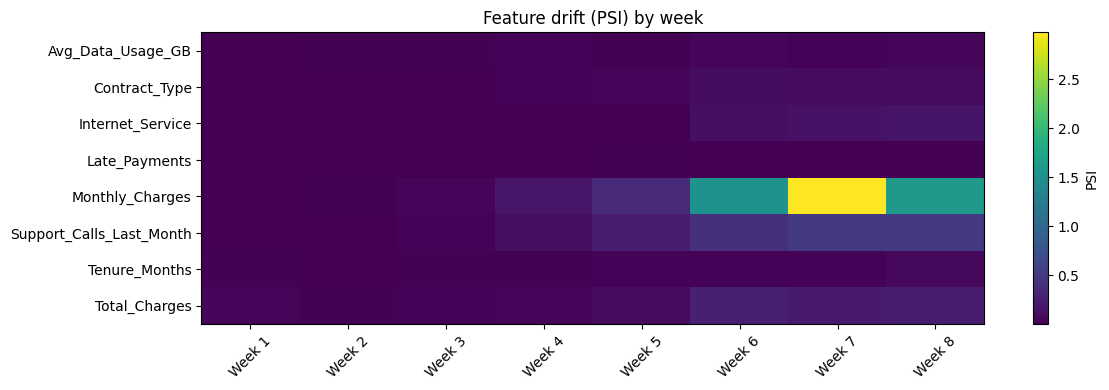

,week,moderate_or_higher,high
0,1,0,0
1,2,0,0
2,3,0,0
3,4,2,0
4,5,2,1
5,6,4,3
6,7,4,2
7,8,4,2


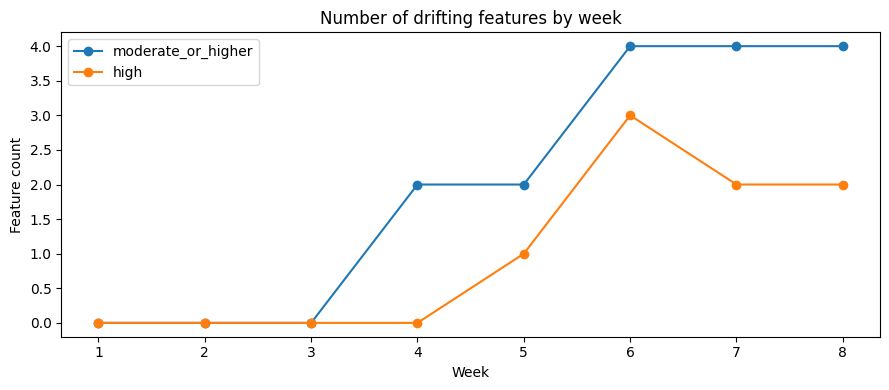

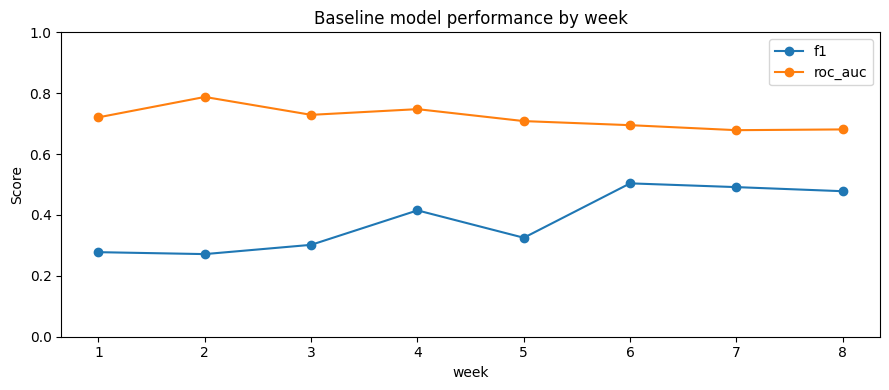

In [8]:
# Drift heatmap (matplotlib; all features and all 8 weeks)
heatmap_data = drift_all.pivot(index="feature", columns="week", values="psi")
fig, ax = plt.subplots(figsize=(12, max(4, len(heatmap_data) * 0.38)))
im = ax.imshow(heatmap_data.to_numpy(), aspect="auto", interpolation="nearest")
ax.set_xticks(range(len(heatmap_data.columns)), [f"Week {w}" for w in heatmap_data.columns], rotation=45)
ax.set_yticks(range(len(heatmap_data.index)), heatmap_data.index)
ax.set_title("Feature drift (PSI) by week")
fig.colorbar(im, ax=ax, label="PSI")
fig.tight_layout()
fig.savefig(REPORT_DIR / "feature_drift_heatmap.png", dpi=160)
plt.show()

# Count features crossing PSI 0.10 and 0.25 per week
drift_counts = drift_all.groupby("week").agg(
    moderate_or_higher=("psi", lambda s: int((s >= 0.10).sum())),
    high=("psi", lambda s: int((s >= 0.25).sum()))
).reset_index()
display(drift_counts)
ax = drift_counts.plot(x="week", y=["moderate_or_higher", "high"], marker="o", figsize=(9,4))
ax.set_title("Number of drifting features by week")
ax.set_xlabel("Week"); ax.set_ylabel("Feature count")
plt.tight_layout()
plt.savefig(REPORT_DIR / "drifting_feature_counts.png", dpi=160)
plt.show()

ax = performance_all.plot(x="week", y=["f1", "roc_auc"], marker="o", figsize=(9,4))
ax.set_title("Baseline model performance by week")
ax.set_ylim(0,1); ax.set_ylabel("Score")
plt.tight_layout()
plt.savefig(REPORT_DIR / "baseline_weekly_performance.png", dpi=160)
plt.show()


## Task 4 — Orchestrated workflow

### 4.1 — Implement the workflow stages and safe promotion gates

The workflow performs ingestion, validation, drift detection, conditional retraining, candidate comparison, conditional promotion, and run-summary recording. Decisions must not use future-week data.

### 4.1.1 — Define schema validation, workflow stages, and safe promotion rules

In [9]:
def validate_week(week_df, reference_df):
    missing = set(reference_df.columns) - set(week_df.columns)
    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")
    if week_df.empty:
        raise ValueError("Weekly dataset is empty.")
    if week_df["Churn"].nunique(dropna=True) < 2:
        raise ValueError("Weekly target must contain both classes for this simulation.")
    return True

def next_model_version(registry):
    versions = []
    for item in registry["models"]:
        try: versions.append(int(item["version"].replace("v", "")))
        except Exception: pass
    return f"v{max(versions + [0]) + 1}"

def safe_promote(candidate_entry):
    registry = read_registry()
    current_version = registry["production_version"]
    candidate_path = PROJECT_ROOT / candidate_entry["model_path"]
    if not candidate_path.exists() or sha256_file(candidate_path) != candidate_entry["sha256"]:
        raise RuntimeError("Candidate missing or checksum invalid; promotion blocked.")
    old_entry = next(m for m in registry["models"] if m["version"] == current_version)
    old_entry["status"] = "archived"
    candidate_entry["status"] = "production"
    registry["models"].append(candidate_entry)
    registry["production_version"] = candidate_entry["version"]
    write_registry(registry)
    return current_version, candidate_entry["version"]

def run_one_week(week, policy, threshold, fault=None):
    start = time.perf_counter()
    registry_before = read_registry()
    production_before = registry_before.get("production_version")
    run = {
        "week": week, "policy": policy, "started_at": utc_now(),
        "production_before": production_before, "production_after": production_before,
        "status": "started", "retraining_triggered": False, "promoted": False,
        "retry_count": 0, "fault_injected": fault
    }
    try:
        ref = pd.read_csv(DATA_DIR / "churn_reference_train.csv")
        # Bounded retry policy for transient ingestion errors only. Schema/data errors are not retried.
        retry_log = []
        attempts = 0
        while True:
            attempts += 1
            try:
                if fault == "transient_ingest" and attempts < 3:
                    raise TimeoutError("simulated transient ingestion timeout")
                weekly = pd.read_csv(DATA_DIR / f"churn_week_{week}.csv")
                break
            except (TimeoutError, ConnectionError) as exc:
                retry_log.append({"attempt": attempts, "error": f"{type(exc).__name__}: {exc}"})
                if attempts >= 3:
                    raise
                time.sleep(0.05 * (2 ** (attempts - 1)))
        run["retry_count"] = attempts - 1
        run["ingestion_attempts"] = attempts
        run["retry_log"] = retry_log
        if fault == "invalid_data":
            weekly = weekly.drop(columns=[weekly.columns[0]])
        validate_week(weekly, ref)
        drift = calculate_drift(ref, weekly)
        drift.to_csv(REPORT_DIR / f"week_{week}_drift.csv", index=False)
        mean_psi = float(drift["psi"].dropna().mean())
        max_psi = float(drift["psi"].dropna().max())
        current_model, current_entry = load_production()
        Xw, yw = get_xy(weekly)
        current_metrics = calculate_metrics(current_model, Xw, yw)
        if policy == "never":
            trigger = False
        elif policy == "weekly":
            trigger = True
        elif policy in ("drift_low", "drift_high"):
            trigger = bool((drift["psi"].fillna(0) >= threshold).any())
        else:
            raise ValueError(f"Unknown policy {policy}")
        run.update({
            "mean_psi": mean_psi, "max_psi": max_psi,
            "drifting_features": int((drift["psi"].fillna(0) >= threshold).sum()),
            "production_metrics": current_metrics,
            "retraining_triggered": trigger
        })
        if trigger:
            historical = [ref]
            source_weeks = ["reference"]
            # Operational decision uses only labels available BEFORE this week.
            # Current-week labels are used later for retrospective reporting, never for promotion.
            for earlier_week in range(1, week):
                historical_df = pd.read_csv(DATA_DIR / f"churn_week_{earlier_week}.csv")
                validate_week(historical_df, ref)
                historical.append(historical_df)
                source_weeks.append(f"week_{earlier_week}")
            training_df = pd.concat(historical, ignore_index=True)
            version = next_model_version(read_registry())
            candidate_model, candidate_entry = train_model(training_df, version, source_weeks)
            candidate_metrics = candidate_entry["metrics"]  # internal held-out split, not current week
            production_reference_f1 = current_entry["metrics"]["f1"]
            production_reference_auc = current_entry["metrics"].get("roc_auc") or 0.0
            candidate_auc = candidate_metrics.get("roc_auc") or 0.0
            # Promote only if at least one primary metric improves meaningfully,
            # while neither F1 nor AUC regresses beyond its tolerance.
            meaningful_gain = (
                candidate_metrics["f1"] >= production_reference_f1 + 0.01 or
                candidate_auc >= production_reference_auc + 0.01
            )
            passed = (
                meaningful_gain and
                candidate_metrics["f1"] >= production_reference_f1 - 0.02 and
                candidate_auc >= production_reference_auc - 0.03
            )
            if fault == "reject_candidate":
                passed = False
            run["candidate_version"] = version
            run["candidate_metrics"] = candidate_metrics
            run["candidate_evaluation"] = "random holdout split from reference + previously labelled weeks only"
            run["candidate_passed"] = bool(passed)
            if passed:
                old, new = safe_promote(candidate_entry)
                run.update({"promoted": True, "promoted_from": old, "promoted_to": new, "decision": "promoted"})
            else:
                run["decision"] = "candidate_rejected"
        else:
            run["decision"] = "no_retraining"
        # Operational escalation uses current-week FEATURES only (no current-week label leakage).
        # Evidence-based rule: escalate if >=2 features have PSI >= 0.25, OR mean PSI >= 0.25.
        severe_features = int((drift["psi"].fillna(0) >= 0.25).sum())
        run["severe_drift_features"] = severe_features
        run["escalation"] = bool(severe_features >= 2 or mean_psi >= 0.25)
        if run["escalation"]:
            run["escalation_reason"] = f"feature-only rule: severe_PSI_features={severe_features}; mean_PSI={mean_psi:.3f}"
        run["status"] = "success"
    except Exception as exc:
        run["status"] = "failed"
        run["error"] = f"{type(exc).__name__}: {exc}"
    finally:
        run["duration_seconds"] = round(time.perf_counter() - start, 4)
        run["finished_at"] = utc_now()
        run["production_after"] = read_registry().get("production_version")
        run["production_unchanged_on_failure"] = (
            run["status"] != "failed" or run["production_before"] == run["production_after"]
        )
        append_json_record(ARTIFACT_DIR / "run_history.json", run)
        with open(LOG_DIR / "workflow.log", "a", encoding="utf-8") as log:
            log.write(json.dumps(run) + "\n")
    return run

print("Workflow functions defined.")


Workflow functions defined.


### 4.2 — Run all eight weeks sequentially

### 4.2.1 — Execute the selected policy week by week and preserve the run history

In [10]:
# Choose one policy for this first run. Later compare all four in Section 6.
ACTIVE_POLICY = "drift_low"   # choices: never, weekly, drift_low, drift_high
ACTIVE_THRESHOLD = 0.10 if ACTIVE_POLICY == "drift_low" else 0.25

# Start this run from a fresh baseline for reproducibility.
initialise_baseline(reset=True)
# Reset only this experiment's run history.
history_path = ARTIFACT_DIR / "run_history.json"
if history_path.exists():
    history_path.unlink()

weekly_runs = []
for w in range(1, 9):
    result = run_one_week(w, ACTIVE_POLICY, ACTIVE_THRESHOLD)
    weekly_runs.append(result)
    print(
        f"Week {w}: {result['status']} | {result.get('decision')} | "
        f"production={result.get('production_after')} | "
        f"escalation={result.get('escalation', False)}"
    )

weekly_runs_df = pd.DataFrame(weekly_runs)
display(weekly_runs_df[[
    "week", "status", "mean_psi", "max_psi", "retraining_triggered",
    "candidate_passed", "promoted", "production_before", "production_after", "escalation"
]].fillna(""))
weekly_runs_df.to_csv(REPORT_DIR / f"workflow_{ACTIVE_POLICY}_summary.csv", index=False)


Week 1: success | no_retraining | production=v1 | escalation=False
Week 2: success | no_retraining | production=v1 | escalation=False
Week 3: success | no_retraining | production=v1 | escalation=False
Week 4: success | promoted | production=v2 | escalation=False
Week 5: success | promoted | production=v3 | escalation=False
Week 6: success | promoted | production=v4 | escalation=True
Week 7: success | promoted | production=v5 | escalation=True
Week 8: success | promoted | production=v6 | escalation=True


,week,status,mean_psi,max_psi,retraining_triggered,candidate_passed,promoted,production_before,production_after,escalation
0,1,success,0.012202,0.038349,False,,False,v1,v1,False
1,2,success,0.009187,0.021832,False,,False,v1,v1,False
2,3,success,0.019440,0.056766,False,,False,v1,v1,False
3,4,success,0.053630,0.185158,True,True,True,v1,v2,False
4,5,success,0.098490,0.360430,True,True,True,v2,v3,False
5,6,success,0.310144,1.528192,True,True,True,v3,v4,True
6,7,success,0.501264,2.981136,True,True,True,v4,v5,True
7,8,success,0.340849,1.601566,True,True,True,v5,v6,True


## Task 5 — Retraining policy study

### 5.1 — Compare all four policies from the same baseline

### 5.1.1 — Run never, weekly, low-threshold, and high-threshold policies

In [11]:
def reset_experiment_state():
    for p in MODEL_DIR.glob("*.joblib"):
        p.unlink()
    for path in [ARTIFACT_DIR / "registry.json", ARTIFACT_DIR / "run_history.json"]:
        if path.exists(): path.unlink()
    initialise_baseline()

policy_specs = [
    ("never", 0.10),
    ("weekly", 0.10),
    ("drift_low", 0.10),
    ("drift_high", 0.25)
]
policy_records = []
for policy_name, threshold in policy_specs:
    print("Running policy:", policy_name)
    reset_experiment_state()
    for w in range(1, 9):
        record = run_one_week(w, policy_name, threshold)
        policy_records.append(record)
    # Preserve the complete eight-week history for this policy before the next reset.
    history_source = ARTIFACT_DIR / "run_history.json"
    if history_source.exists():
        shutil.copy2(history_source, REPORT_DIR / f"run_history_{policy_name}.json")

policy_results = pd.DataFrame(policy_records)
policy_results.to_csv(REPORT_DIR / "policy_weekly_results.csv", index=False)
policy_results.to_json(REPORT_DIR / "policy_weekly_results.json", orient="records", indent=2)

summary_rows = []
for policy_name, group in policy_results.groupby("policy"):
    f1_values = [
        row.get("production_metrics", {}).get("f1")
        for row in group.to_dict("records")
        if isinstance(row.get("production_metrics"), dict)
    ]
    attempts = int(group["retraining_triggered"].fillna(False).sum())
    promotions = int(group["promoted"].fillna(False).sum())
    summary_rows.append({
        "policy": policy_name,
        "weeks": len(group),
        "failed_runs": int((group["status"] == "failed").sum()),
        "retraining_attempts": attempts,
        "promotions": promotions,
        "mean_weekly_f1": float(np.mean(f1_values)) if f1_values else np.nan,
        "worst_weekly_f1": float(np.min(f1_values)) if f1_values else np.nan,
        "retraining_cost_units": attempts * 10,
        "promotion_cost_units": promotions * 2,
        "total_cost_units": attempts * 10 + promotions * 2
    })
policy_summary = pd.DataFrame(summary_rows).sort_values("policy")
policy_summary.to_csv(REPORT_DIR / "policy_comparison.csv", index=False)
display(policy_summary)


Running policy: never
Running policy: weekly
Running policy: drift_low
Running policy: drift_high


,policy,weeks,failed_runs,retraining_attempts,promotions,mean_weekly_f1,worst_weekly_f1,retraining_cost_units,promotion_cost_units,total_cost_units
0,drift_high,8,0,4,4,0.400831,0.271429,40,8,48
1,drift_low,8,0,5,5,0.401665,0.271429,50,10,60
2,never,8,0,0,0,0.383087,0.271429,0,0,0
3,weekly,8,0,8,5,0.400649,0.271429,80,10,90


### 5.2 — Produce the policy comparison table and timeline chart

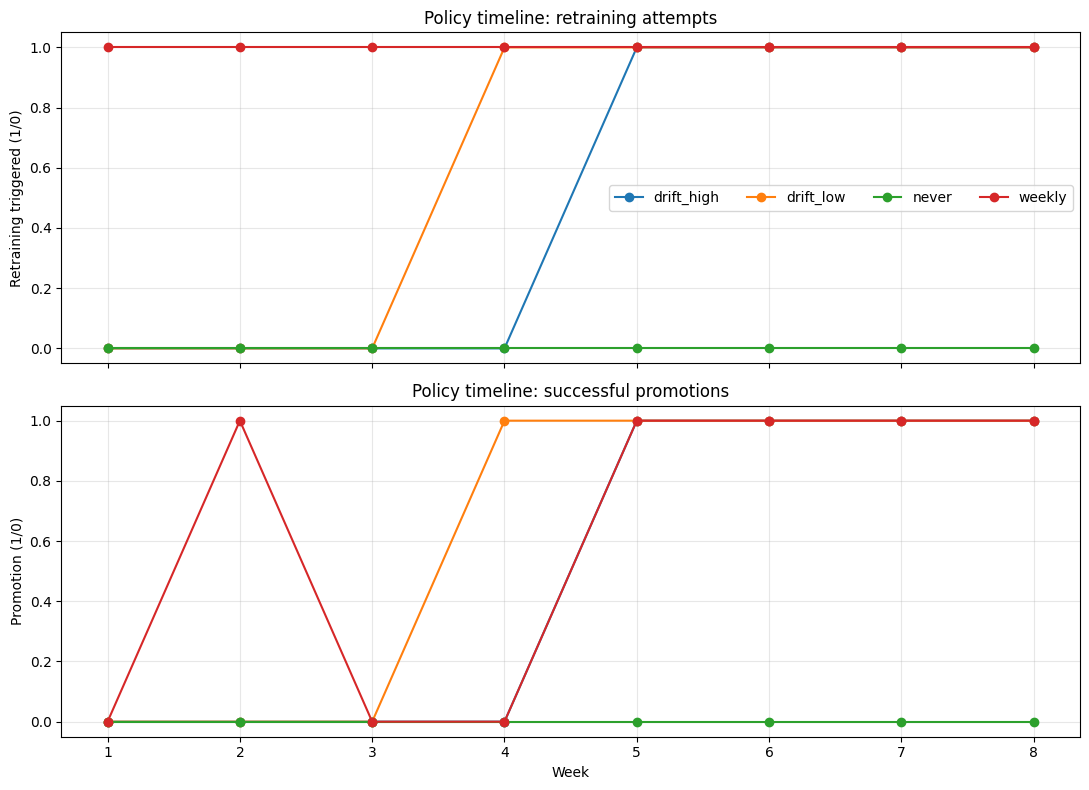

In [12]:
# Policy timeline: retraining attempts and promotions by week.
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
for policy_name, group in policy_results.groupby("policy"):
    group = group.sort_values("week")
    axes[0].plot(group["week"], group["retraining_triggered"].astype(int), marker="o", label=policy_name)
    axes[1].plot(group["week"], group["promoted"].astype(int), marker="o", label=policy_name)
axes[0].set_ylabel("Retraining triggered (1/0)")
axes[0].set_title("Policy timeline: retraining attempts")
axes[1].set_ylabel("Promotion (1/0)")
axes[1].set_xlabel("Week")
axes[1].set_title("Policy timeline: successful promotions")
for ax in axes:
    ax.set_xticks(range(1,9))
    ax.grid(True, alpha=0.3)
axes[0].legend(ncol=4)
fig.tight_layout()
fig.savefig(REPORT_DIR / "policy_timeline.png", dpi=160)
plt.show()


## Task 6 — Failure handling

### 6.1 — Define and implement retry behavior

Retry transient ingestion/transport errors up to two retries (three total attempts) with exponential backoff. Do not retry deterministic schema-validation errors.

### 6.1.1 — Retry transient failures only; fail fast on invalid data

In [13]:
def retry_transient(operation, max_retries=2, base_delay_seconds=0.05):
    attempts = 0
    retry_log = []
    while True:
        attempts += 1
        try:
            result = operation()
            return result, {"attempts": attempts, "retries": attempts - 1, "log": retry_log}
        except (TimeoutError, ConnectionError) as exc:
            retry_log.append({"attempt": attempts, "error": f"{type(exc).__name__}: {exc}"})
            if attempts > max_retries:
                raise
            time.sleep(base_delay_seconds * (2 ** (attempts - 1)))

_simulated_state = {"calls": 0}
def flaky_operation():
    _simulated_state["calls"] += 1
    if _simulated_state["calls"] < 3:
        raise TimeoutError("simulated temporary ingestion timeout")
    return "ingestion succeeded"

retry_result, retry_evidence = retry_transient(flaky_operation)
retry_evidence["result"] = retry_result
print(json.dumps(retry_evidence, indent=2))
(REPORT_DIR / "retry_policy_evidence.json").write_text(json.dumps(retry_evidence, indent=2), encoding="utf-8")
assert retry_evidence["attempts"] == 3 and retry_result == "ingestion succeeded"


{
  "attempts": 3,
  "retries": 2,
  "log": [
    {
      "attempt": 1,
      "error": "TimeoutError: simulated temporary ingestion timeout"
    },
    {
      "attempt": 2,
      "error": "TimeoutError: simulated temporary ingestion timeout"
    }
  ],
  "result": "ingestion succeeded"
}


### 6.2 — Inject at least two faults and prove production remains unchanged

### 6.2.1 — Fault 1: invalid input; Fault 2: rejected candidate; verify registry and endpoint versions

In [14]:
# Fault 1: invalid schema must fail closed; neither registry nor endpoint model version may change.
reset_experiment_state()
endpoint_before = endpoint_predict(sample_record, cold=True)
before = read_registry()["production_version"]
fault_invalid = run_one_week(3, "weekly", 0.10, fault="invalid_data")
after = read_registry()["production_version"]
endpoint_after = endpoint_predict(sample_record, cold=True)
fault_invalid["endpoint_version_before"] = endpoint_before["production_version"]
fault_invalid["endpoint_version_after"] = endpoint_after["production_version"]
fault_invalid["endpoint_unchanged"] = endpoint_before["production_version"] == endpoint_after["production_version"]
print("Invalid-data fault:", fault_invalid["status"], fault_invalid.get("error"))
print("Registry before/after:", before, after)
assert fault_invalid["status"] == "failed"
assert before == after and fault_invalid["endpoint_unchanged"]

# Fault 2: candidate quality gate is forced to reject. It is a safe completed run, not a pipeline crash.
reset_experiment_state()
endpoint_before = endpoint_predict(sample_record, cold=True)
before = read_registry()["production_version"]
fault_reject = run_one_week(5, "weekly", 0.10, fault="reject_candidate")
after = read_registry()["production_version"]
endpoint_after = endpoint_predict(sample_record, cold=True)
fault_reject["endpoint_version_before"] = endpoint_before["production_version"]
fault_reject["endpoint_version_after"] = endpoint_after["production_version"]
fault_reject["endpoint_unchanged"] = endpoint_before["production_version"] == endpoint_after["production_version"]
print("Candidate rejection:", fault_reject["status"], fault_reject.get("decision"))
assert fault_reject["status"] == "success"
assert fault_reject.get("promoted") is False
assert before == after and fault_reject["endpoint_unchanged"]

# Fault 3: transient ingestion timeout retries twice, then succeeds. This proves the configured retry path.
reset_experiment_state()
fault_retry = run_one_week(2, "never", 0.10, fault="transient_ingest")
print("Transient fault:", fault_retry["status"], "retries=", fault_retry.get("retry_count"))
assert fault_retry["status"] == "success" and fault_retry["retry_count"] == 2

fault_evidence = pd.DataFrame([fault_invalid, fault_reject, fault_retry])
fault_evidence.to_json(REPORT_DIR / "fault_injection_evidence.json", orient="records", indent=2)
display(fault_evidence[["week","status","fault_injected","error","decision","promoted","retry_count",
                        "production_before","production_after","production_unchanged_on_failure",
                        "endpoint_version_before","endpoint_version_after","endpoint_unchanged"]].fillna(""))


Invalid-data fault: failed ValueError: Missing required columns: ['Customer_ID']
Registry before/after: v1 v1
Candidate rejection: success candidate_rejected
Transient fault: success retries= 2


,week,status,fault_injected,error,decision,promoted,retry_count,production_before,production_after,production_unchanged_on_failure,endpoint_version_before,endpoint_version_after,endpoint_unchanged
0,3,failed,invalid_data,ValueError: Missing required columns: ['Custom...,,False,0,v1,v1,True,v1,v1,True
1,5,success,reject_candidate,,candidate_rejected,False,0,v1,v1,True,v1,v1,True
2,2,success,transient_ingest,,no_retraining,False,2,v1,v1,True,,,


## Task 7 — Escalation design

### 7.1 — Define an objective, feature-only escalation condition

The operational escalation rule uses current-week feature data only, avoiding current-week label leakage.

### 7.1.1 — Check that escalation fired and save event-level evidence

In [15]:
# Evidence is taken from the selected clean eight-week workflow and the policy study.
escalations = policy_results[policy_results["escalation"].fillna(False) == True].copy()
print("Escalation events across policy experiments:", len(escalations))
if len(escalations):
    display(escalations[["policy","week","mean_psi","severe_drift_features","escalation_reason"]])
    escalations.to_json(REPORT_DIR / "escalation_policy_study_evidence.json", orient="records", indent=2)
else:
    print("No policy escalation fired; inspect observed drift before changing the rule.")


Escalation events across policy experiments: 12


,policy,week,mean_psi,severe_drift_features,escalation_reason
5,never,6,0.310144,3,feature-only rule: severe_PSI_features=3; mean...
6,never,7,0.501264,2,feature-only rule: severe_PSI_features=2; mean...
7,never,8,0.340849,2,feature-only rule: severe_PSI_features=2; mean...
13,weekly,6,0.310144,3,feature-only rule: severe_PSI_features=3; mean...
14,weekly,7,0.501264,2,feature-only rule: severe_PSI_features=2; mean...
15,weekly,8,0.340849,2,feature-only rule: severe_PSI_features=2; mean...
21,drift_low,6,0.310144,3,feature-only rule: severe_PSI_features=3; mean...
22,drift_low,7,0.501264,2,feature-only rule: severe_PSI_features=2; mean...
23,drift_low,8,0.340849,2,feature-only rule: severe_PSI_features=2; mean...
29,drift_high,6,0.310144,3,feature-only rule: severe_PSI_features=3; mean...


### 1.5 — Save baseline and promoted-model registry evidence

### 1.5.1 — Save model metadata, metrics, checksums, and version status

In [16]:
final_registry = read_registry()
(ARTIFACT_DIR / "registry_evidence.json").write_text(json.dumps(final_registry, indent=2), encoding="utf-8")
print("Production version:", final_registry["production_version"])
display(pd.DataFrame(final_registry["models"])[["version","status","source_weeks","metrics","sha256"]])
print("\nEvidence files created:")
for p in sorted(REPORT_DIR.glob("*")):
    print("-", p.name)


Production version: v1


,version,status,source_weeks,metrics,sha256
0,v1,production,[reference],"{'accuracy': 0.7933333333333333, 'precision': ...",485d37fedd6c8e0a49cab3b818fbfa0f72706121c86dcf...



Evidence files created:
- baseline_metrics.json
- baseline_weekly_performance.csv
- baseline_weekly_performance.png
- data_inventory.json
- drifting_feature_counts.png
- endpoint_latency_benchmark.csv
- endpoint_model_switch_evidence.json
- escalation_evidence.json
- escalation_policy_study_evidence.json
- fault_injection_evidence.json
- feature_drift_all_weeks.csv
- feature_drift_heatmap.png
- final_eight_week_run_history.csv
- final_eight_week_run_history.json
- final_escalation_evidence.json
- orchestration_graph.png
- policy_comparison.csv
- policy_timeline.png
- policy_weekly_results.csv
- policy_weekly_results.json
- retry_policy_evidence.json
- run_history_drift_high.json
- run_history_drift_low.json
- run_history_never.json
- run_history_weekly.json
- training_config.json
- week_1_drift.csv
- week_2_drift.csv
- week_3_drift.csv
- week_4_drift.csv
- week_5_drift.csv
- week_6_drift.csv
- week_7_drift.csv
- week_8_drift.csv
- workflow_drift_low_summary.csv


### 4.3 — Create the orchestrator graph evidence

### 4.3.1 — Save the orchestrator graph screenshot as a PNG

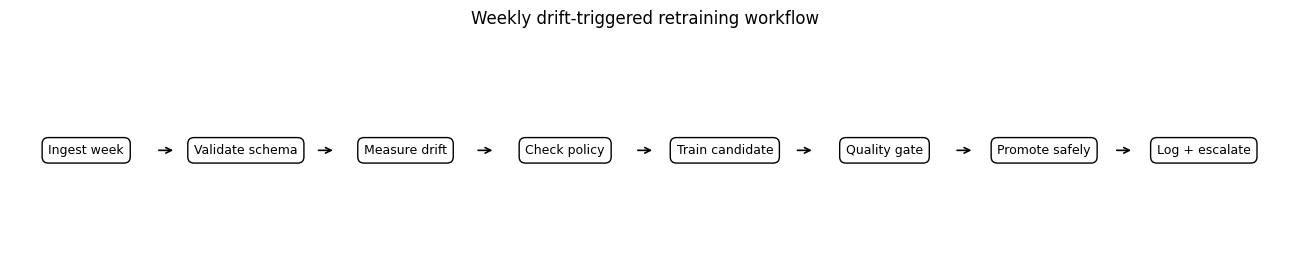

Saved: D:\drift-triggered-retraining\artifacts\reports\orchestration_graph.png


In [17]:
# Save a simple workflow graph image for the report/demo.
fig, ax = plt.subplots(figsize=(13, 2.8))
ax.axis("off")
steps = ["Ingest week", "Validate schema", "Measure drift", "Check policy", "Train candidate", "Quality gate", "Promote safely", "Log + escalate"]
xs = np.linspace(0.06, 0.94, len(steps))
for i, (x, label) in enumerate(zip(xs, steps)):
    ax.text(x, 0.5, label, ha="center", va="center", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="black"),
            transform=ax.transAxes)
    if i < len(steps)-1:
        ax.annotate("", xy=(xs[i+1]-0.055, 0.5), xytext=(x+0.055, 0.5),
                    xycoords=ax.transAxes, textcoords=ax.transAxes,
                    arrowprops=dict(arrowstyle="->", lw=1.2))
ax.set_title("Weekly drift-triggered retraining workflow", pad=12)
fig.tight_layout()
fig.savefig(REPORT_DIR / "orchestration_graph.png", dpi=180, bbox_inches="tight")
plt.show()
print("Saved:", REPORT_DIR / "orchestration_graph.png")


## Final reporting — interpretation questions

Use the actual outputs from Tasks 3 and 5 to answer these questions in the report.

## Final evidence check — run this section last

This section runs the recommended policy from a clean baseline, preserves the eight-week run history, and checks the required evidence files.

### Final verification — preserve all eight run records and assert the evidence checks

In [18]:
# Final reproducible eight-week run; this is the run history to submit.
FINAL_POLICY = "drift_high"
FINAL_THRESHOLD = 0.25
reset_experiment_state()
final_weekly_runs = []
for w in range(1, 9):
    rec = run_one_week(w, FINAL_POLICY, FINAL_THRESHOLD)
    final_weekly_runs.append(rec)
    print(f"Week {w}: status={rec['status']} decision={rec.get('decision')} production={rec.get('production_after')} escalation={rec.get('escalation', False)}")

final_runs_df = pd.DataFrame(final_weekly_runs)
final_runs_df.to_csv(REPORT_DIR / "final_eight_week_run_history.csv", index=False)
# Preserve the eight records in the canonical run-history path; policy runs are saved separately.
(ARTIFACT_DIR / "run_history.json").write_text(json.dumps(final_weekly_runs, indent=2, default=str), encoding="utf-8")
final_registry = read_registry()
(ARTIFACT_DIR / "registry_evidence.json").write_text(json.dumps(final_registry, indent=2), encoding="utf-8")
(ARTIFACT_DIR / "final_registry_evidence.json").write_text(json.dumps(final_registry, indent=2), encoding="utf-8")

# Endpoint switching proof: same handler, registry pointer changes only via the promotion workflow.
endpoint_cache_before = endpoint_predict(sample_record, cold=True)
versions_in_registry = [m["version"] for m in final_registry["models"]]
production_version = final_registry["production_version"]
endpoint_after_final = endpoint_predict(sample_record, cold=True)
switch_evidence = {
    "handler": "endpoint_predict (same prediction logic throughout)",
    "production_version_after_workflow": production_version,
    "registered_versions": versions_in_registry,
    "endpoint_response_version": endpoint_after_final["production_version"],
    "prediction": endpoint_after_final["prediction"],
    "churn_probability": endpoint_after_final["churn_probability"],
    "baseline_registered": any(m["version"] == "v1" for m in final_registry["models"]),
    "promoted_version_exists": any(m["version"] != "v1" and m["status"] == "production" for m in final_registry["models"]),
    "endpoint_resolves_current_production": endpoint_after_final["production_version"] == production_version
}
(REPORT_DIR / "endpoint_model_switch_evidence.json").write_text(json.dumps(switch_evidence, indent=2), encoding="utf-8")
(REPORT_DIR / "final_eight_week_run_history.json").write_text(json.dumps(final_weekly_runs, indent=2, default=str), encoding="utf-8")
(REPORT_DIR / "final_escalation_evidence.json").write_text(json.dumps([r for r in final_weekly_runs if r.get("escalation")], indent=2), encoding="utf-8")

assert len(final_weekly_runs) == 8
assert all(r["week"] == i for i, r in enumerate(final_weekly_runs, start=1))
assert all(r["status"] == "success" for r in final_weekly_runs)
assert switch_evidence["baseline_registered"]
assert switch_evidence["promoted_version_exists"], "No promoted model exists; inspect candidate quality gate and weekly evidence."
assert switch_evidence["endpoint_resolves_current_production"]
assert any(r.get("escalation") for r in final_weekly_runs), "Escalation must fire in at least one simulated week."
print("\nFINAL CHECKS PASSED")
print("Canonical run history records:", len(json.loads((ARTIFACT_DIR / "run_history.json").read_text())))
print("Registry versions:", versions_in_registry)
print("Current production:", production_version)
print("Escalation weeks:", [r["week"] for r in final_weekly_runs if r.get("escalation")])
print("Endpoint switch evidence:", json.dumps(switch_evidence, indent=2))


Week 1: status=success decision=no_retraining production=v1 escalation=False
Week 2: status=success decision=no_retraining production=v1 escalation=False
Week 3: status=success decision=no_retraining production=v1 escalation=False
Week 4: status=success decision=no_retraining production=v1 escalation=False
Week 5: status=success decision=promoted production=v2 escalation=False
Week 6: status=success decision=promoted production=v3 escalation=True
Week 7: status=success decision=promoted production=v4 escalation=True
Week 8: status=success decision=promoted production=v5 escalation=True

FINAL CHECKS PASSED
Canonical run history records: 8
Registry versions: ['v1', 'v2', 'v3', 'v4', 'v5']
Current production: v5
Escalation weeks: [6, 7, 8]
Endpoint switch evidence: {
  "handler": "endpoint_predict (same prediction logic throughout)",
  "production_version_after_workflow": "v5",
  "registered_versions": [
    "v1",
    "v2",
    "v3",
    "v4",
    "v5"
  ],
  "endpoint_response_version":